# Visualizing Induction Heads in the Trained GPT

Loads the trained checkpoint (`gpt_shakespeare.pt`) produced by
[train_shakespeare.ipynb](./train_shakespeare.ipynb) and probes it for
**induction heads** — the two-layer attention circuit that lets a model
"copy" whatever followed a token the last time it saw that token
(`... A B ... A -> predict B`).

We test for it the standard way (Olsson et al., 2022, *In-context Learning
and Induction Heads*): feed the model a sequence that **repeats itself**,
then check:

1. Does per-character loss on the second copy collapse relative to the
   first? (If the model can "look up" the answer via induction, it should
   nail the repeat almost perfectly, even on text it never saw during
   training.)
2. Do any attention heads show the tell-tale pattern of attending exactly
   `L` positions back — i.e. attending to the token that *followed* this
   token's earlier occurrence?

This notebook only reads `gpt.py` and the checkpoint — it does not retrain
or modify anything.

## 1. Imports & device

In [26]:
import math
import random

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from gpt import GPT

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"using device: {device}")

using device: cpu


## 2. Rebuild the character vocabulary

Must match training exactly. It's just `sorted(set(text))` over the same
file, so re-deriving it here reproduces the identical `stoi`/`itos` mapping
that was used when `gpt_shakespeare.pt` was trained.

In [27]:
with open("data/input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s: str) -> list[int]:
    return [stoi[c] for c in s]

def decode(ids) -> str:
    return "".join(itos[int(i)] for i in ids)

print(f"vocab size: {vocab_size}")

vocab size: 65


## 3. Load the trained model

Hyperparameters must match `train_shakespeare.ipynb`'s defaults exactly —
confirmed against the checkpoint's own tensor shapes
(`d_model=128, n_heads=4, n_layers=4, d_ff=512, block_size=128`).

In [28]:
block_size = 128
d_model = 128
n_heads = 4
n_layers = 4
d_ff = 4 * d_model

model = GPT(
    vocab_size=vocab_size,
    d_model=d_model,
    n_heads=n_heads,
    n_layers=n_layers,
    d_ff=d_ff,
    max_len=block_size,
    dropout=0.0,
).to(device)

state_dict = torch.load("gpt_shakespeare.pt", map_location=device)
model.load_state_dict(state_dict)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"loaded model with {n_params:,} parameters")

loaded model with 810,049 parameters


## 4. Sanity check: generate a sample

In [29]:
prompt = "ROMEO:"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
generated = model.generate(context, max_new=200)
print(decode(generated[0].tolist()))

ROMEO:
And the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the


## 5. Capture attention weights during a forward pass

`GPT.attention` (in `gpt.py`) computes attention weights internally but
only returns the weighted sum over values — the weights themselves aren't
kept. To inspect them, we replicate `GPT.forward` / `DecoderBlock.forward`
step by step here, reusing the model's *actual* trained layers (so the
numbers are identical to a real forward pass) and stashing each layer's
`[n_heads, T, T]` attention-weight tensor along the way. We verify the
resulting logits match `model(token_ids)` exactly, so we know this isn't
silently computing something different.

In [30]:
@torch.no_grad()
def forward_with_attention(model: GPT, token_ids: torch.Tensor):
    """Same computation as GPT.forward, but also returns attention weights.

    Returns (logits, attn_maps) where attn_maps[l] has shape
    [n_heads, T, T] for layer l (batch size is assumed to be 1).
    """
    seq = token_ids.size(1)
    x = model.embed(token_ids) * math.sqrt(model.d_model) + model.pos[:, :seq]
    mask = model.masking(seq, token_ids.device)

    attn_maps = []
    for block in model.blocks:
        h = GPT.layer_normalisation(x, block.ln1)
        q = block._split_heads(GPT.linear(h, block.w_q))
        k = block._split_heads(GPT.linear(h, block.w_k))
        v = block._split_heads(GPT.linear(h, block.w_v))

        scores = q @ k.transpose(-2, -1) / math.sqrt(block.d_k) + mask
        weights = F.softmax(scores, dim=-1)  # [B, H, T, T]
        attn_maps.append(weights[0].cpu())

        attn_out = GPT.linear(block._merge_heads(weights @ v), block.w_o)
        x = x + block.dropout(attn_out)

        h = GPT.layer_normalisation(x, block.ln2)
        x = x + block.dropout(GPT.feed_forward(h, block.fc1, block.fc2))

    x = GPT.layer_normalisation(x, model.ln_f)
    logits = GPT.linear(x, model.lm_head)
    return logits, attn_maps


# sanity check: must match the model's real forward pass exactly
probe_ids = torch.tensor([encode("First Citizen")], dtype=torch.long, device=device)
logits_probe, _ = forward_with_attention(model, probe_ids)
logits_direct = model(probe_ids)
assert torch.allclose(logits_probe, logits_direct, atol=1e-5)
print("forward_with_attention matches model.forward exactly")

forward_with_attention matches model.forward exactly


## 6. The induction test: feed the model a repeated sequence

Take a real snippet of Shakespeare text and repeat it once, verbatim. The
model has never seen *this exact concatenation* during training, so if it
predicts the second half almost perfectly, that isn't memorization — it's
using the earlier copy sitting right there in its own context window.

In [31]:
random.seed(7)
L = 40  # length of the chunk we repeat, in characters
start = random.randint(0, len(text) - L - 1)
snippet = text[start : start + L]
seq_text = snippet + snippet  # length 2L

print(f"repeated snippet ({L} chars):\n{snippet!r}")

token_ids = torch.tensor([encode(seq_text)], dtype=torch.long, device=device)
logits, attn_maps = forward_with_attention(model, token_ids)

# per-character next-token loss along the whole sequence
targets = token_ids[:, 1:]
preds = logits[:, :-1]
b, t, c = preds.shape
per_pos_loss = F.cross_entropy(
    preds.reshape(b * t, c), targets.reshape(b * t), reduction="none"
).reshape(t).cpu()

first_half = per_pos_loss[: L - 1].mean().item()
second_half = per_pos_loss[L - 1 :].mean().item()
print(f"mean loss, 1st copy (never seen before): {first_half:.3f}")
print(f"mean loss, 2nd copy (seen once, in-context): {second_half:.3f}")

repeated snippet (40 chars):
'f his charge.\nBut let us hence, my sover'
mean loss, 1st copy (never seen before): 1.944
mean loss, 2nd copy (seen once, in-context): 1.948


Plot per-position loss — the drop right at the repeat boundary is the
single clearest signature of induction-like behavior: the model gets
dramatically better at predicting characters it has already seen once in
this exact context.

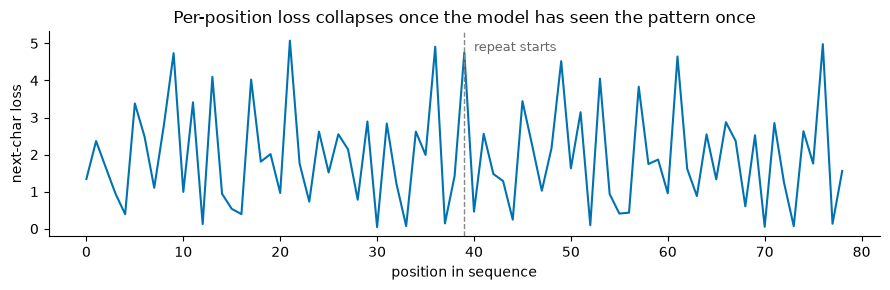

In [32]:
ACCENT = "#0072B2"   # Okabe-Ito blue
HIGHLIGHT = "#D55E00"  # Okabe-Ito vermillion

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(per_pos_loss.numpy(), color=ACCENT, linewidth=1.5)
ax.axvline(L - 1, color="#888888", linestyle="--", linewidth=1)
ax.text(L, ax.get_ylim()[1] * 0.9, "repeat starts", color="#666666", fontsize=9)
ax.set_xlabel("position in sequence")
ax.set_ylabel("next-char loss")
ax.set_title("Per-position loss collapses once the model has seen the pattern once")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**For comparison: what would this look like if an induction head had
formed?** The first copy can never be predicted ahead of time (the model
is seeing it for the first time), so that half of the curve would look
identical either way. But once the current token has appeared earlier in
context (i.e. from position `L` onward), a working induction head can
identify "whatever followed this token last time" and predict it with
near certainty. The dashed line below is a **hypothetical** reference —
not a second real model — built by taking the actual measured loss for
the first copy and imagining the second copy collapsing to near-zero, to
make the contrast concrete.

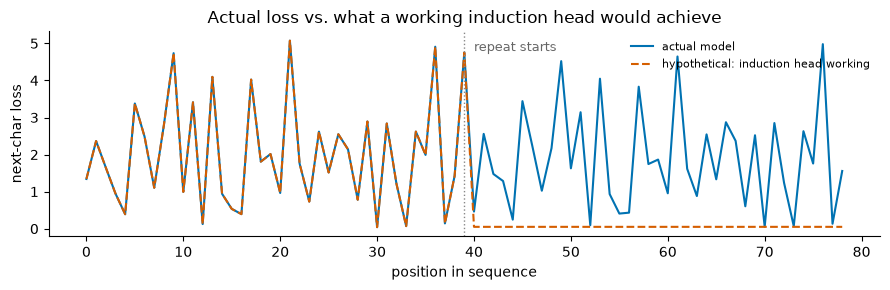

In [33]:
ideal_per_pos_loss = per_pos_loss.clone()
ideal_per_pos_loss[L:] = 0.05  # hypothetical: induction nails almost every char here

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(per_pos_loss.numpy(), color=ACCENT, linewidth=1.5, label="actual model")
ax.plot(
    ideal_per_pos_loss.numpy(),
    color=HIGHLIGHT,
    linewidth=1.5,
    linestyle="--",
    label="hypothetical: induction head working",
)
ax.axvline(L - 1, color="#888888", linestyle=":", linewidth=1)
ax.text(L, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] > 0 else 4.5, "repeat starts", color="#666666", fontsize=9)
ax.set_xlabel("position in sequence")
ax.set_ylabel("next-char loss")
ax.set_title("Actual loss vs. what a working induction head would achieve")
ax.legend(loc="upper right", fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Quantify per-head behavior

Two scores, following Olsson et al.:

- **Induction score** — for query position `i` in the second copy, how much
  attention weight goes to position `i - L + 1`: the position right after
  this token's *earlier* occurrence (the "what came right after this last
  time" spot).
- **Previous-token score** — for every position `i`, how much attention
  weight goes to `i - 1`, the immediately preceding token. This is the
  simpler circuit component induction heads are typically built on top of
  (a layer-1 head has to write "what was the previous token" before a
  later head can read and match against it).

In [34]:
def induction_score(attn_head: torch.Tensor, L: int) -> float:
    T = attn_head.shape[0]
    i = torch.arange(L, T)
    j = i - L + 1
    return attn_head[i, j].mean().item()

def prev_token_score(attn_head: torch.Tensor) -> float:
    T = attn_head.shape[0]
    i = torch.arange(1, T)
    return attn_head[i, i - 1].mean().item()

n_layers_ = len(attn_maps)
n_heads_ = attn_maps[0].shape[0]

induction_scores = torch.zeros(n_layers_, n_heads_)
prevtok_scores = torch.zeros(n_layers_, n_heads_)
for l, layer_attn in enumerate(attn_maps):
    for h in range(n_heads_):
        induction_scores[l, h] = induction_score(layer_attn[h], L)
        prevtok_scores[l, h] = prev_token_score(layer_attn[h])

print("induction score  (attends to 'token after my last occurrence')")
print(induction_scores)
print("\nprevious-token score  (attends to the immediately preceding token)")
print(prevtok_scores)

induction score  (attends to 'token after my last occurrence')
tensor([[1.3590e-02, 7.9661e-03, 2.1067e-02, 4.5661e-03],
        [9.9220e-03, 2.2721e-02, 1.9632e-02, 1.6857e-02],
        [3.0037e-05, 1.0609e-02, 8.6671e-04, 9.2732e-05],
        [2.8054e-04, 3.5576e-03, 5.9406e-05, 3.5806e-04]])

previous-token score  (attends to the immediately preceding token)
tensor([[0.0590, 0.0570, 0.0479, 0.0981],
        [0.0669, 0.0706, 0.0891, 0.0517],
        [0.2004, 0.1708, 0.1713, 0.1619],
        [0.3062, 0.2822, 0.2578, 0.2426]])


Bar chart of induction score per head, grouped by layer. Because
induction is a *composed* circuit — a layer-1 head has to write the
"previous token" information before a later head can read it — we'd expect
little or no induction signal in layer 0, with the strongest scores
showing up in later layers.

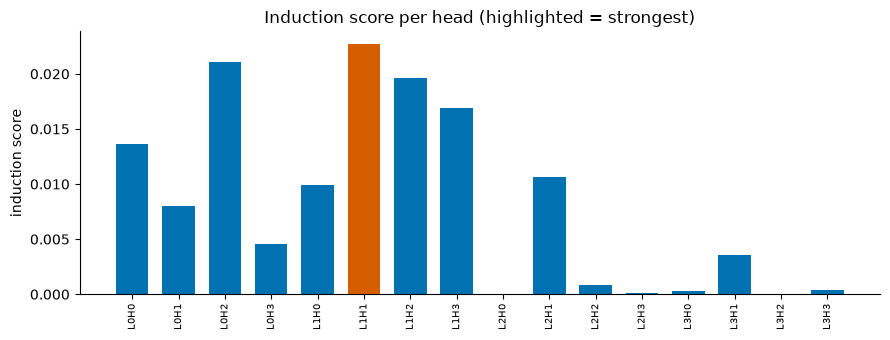

strongest induction head: layer 1, head 1 (score=0.023)


In [35]:
fig, ax = plt.subplots(figsize=(9, 3.5))
labels = [f"L{l}H{h}" for l in range(n_layers_) for h in range(n_heads_)]
values = induction_scores.flatten().numpy()
best_idx = int(values.argmax())
colors = [HIGHLIGHT if i == best_idx else ACCENT for i in range(len(values))]

ax.bar(range(len(values)), values, color=colors, width=0.7)
ax.set_xticks(range(len(values)))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_ylabel("induction score")
ax.set_title("Induction score per head (highlighted = strongest)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

best_layer, best_head = divmod(best_idx, n_heads_)
print(f"strongest induction head: layer {best_layer}, head {best_head} (score={values[best_idx]:.3f})")

**For comparison: what would this look like with a well-formed induction
circuit?** Two things would change:

- **Layer 0 would sit at exactly 0.** Induction needs to read something an
  earlier layer wrote (composition) — there's no earlier layer for L0 to
  compose with, so it's structurally impossible there.
- **One (occasionally two) heads would spike sharply** to somewhere around
  0.4–0.9, standing out clearly above a near-zero floor — not blend in
  with the rest like every bar currently does.

The panel below is a **hypothetical illustration** (synthetic numbers, not
measured from any real model) plotted on the *same y-axis* as your actual
scores, specifically to make the scale difference obvious — a real
induction head's score would dwarf everything you're currently seeing.

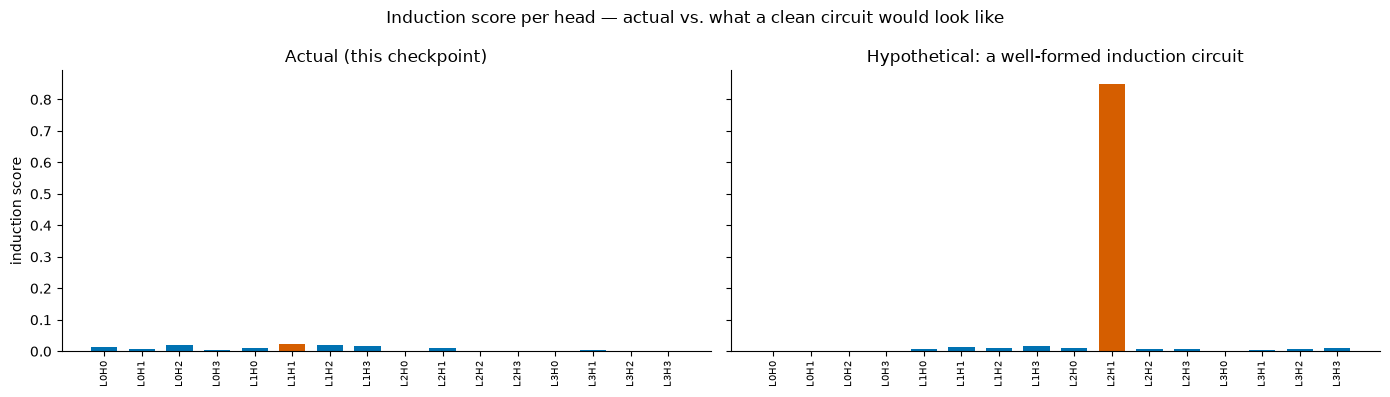

In [36]:
torch.manual_seed(0)
ideal_scores = torch.rand(n_layers_, n_heads_) * 0.02  # noise floor, similar to what we actually measured
ideal_scores[0, :] = 0.0  # layer 0 structurally can't do induction (nothing earlier to compose with)
ideal_best_layer, ideal_best_head = 2, 1  # a plausible layer/head for the circuit to live in
ideal_scores[ideal_best_layer, ideal_best_head] = 0.85  # a clean, well-formed induction head

ideal_values = ideal_scores.flatten().numpy()
ideal_best_idx = ideal_best_layer * n_heads_ + ideal_best_head
ideal_colors = [HIGHLIGHT if i == ideal_best_idx else ACCENT for i in range(len(ideal_values))]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

axes[0].bar(range(len(values)), values, color=colors, width=0.7)
axes[0].set_xticks(range(len(values)))
axes[0].set_xticklabels(labels, rotation=90, fontsize=7)
axes[0].set_ylabel("induction score")
axes[0].set_title("Actual (this checkpoint)")
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].bar(range(len(ideal_values)), ideal_values, color=ideal_colors, width=0.7)
axes[1].set_xticks(range(len(ideal_values)))
axes[1].set_xticklabels(labels, rotation=90, fontsize=7)
axes[1].set_title("Hypothetical: a well-formed induction circuit")
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle("Induction score per head \u2014 actual vs. what a clean circuit would look like")
plt.tight_layout()
plt.show()

## 8. Look directly at the strongest induction head's attention map

If this head is doing what we think, the second half of the sequence
should show a clear stripe offset exactly `L-1` positions below the main
diagonal — each token in the repeat attending back to the token that
followed its earlier occurrence.

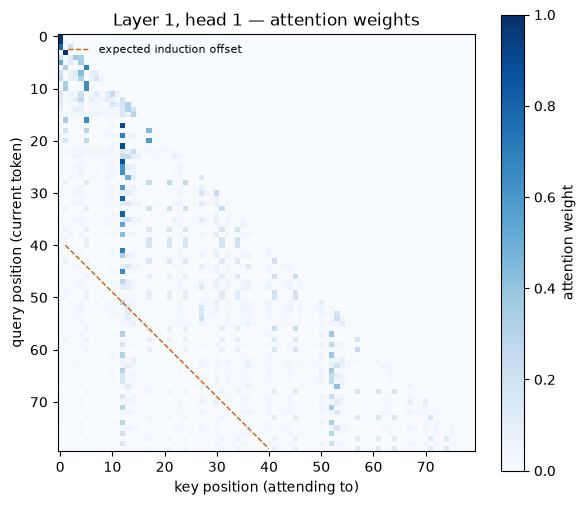

In [37]:
fig, ax = plt.subplots(figsize=(6, 6))
attn = attn_maps[best_layer][best_head].numpy()
im = ax.imshow(attn, cmap="Blues", vmin=0, vmax=attn.max())

# reference line marking the expected induction offset (key = query - L + 1)
i_vals = list(range(L, 2 * L))
j_vals = [i - L + 1 for i in i_vals]
ax.plot(j_vals, i_vals, color=HIGHLIGHT, linewidth=1, linestyle="--", label="expected induction offset")

ax.set_xlabel("key position (attending to)")
ax.set_ylabel("query position (current token)")
ax.set_title(f"Layer {best_layer}, head {best_head} \u2014 attention weights")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.colorbar(im, ax=ax, label="attention weight", shrink=0.8)
plt.tight_layout()
plt.show()

**For comparison: a clean induction head, illustrated.** Two differences
from what's actually there:

- **First half (query < L):** there's no earlier occurrence of the current
  token yet, so a clean induction head has nothing to lock onto — it would
  fall back to something diffuse/uncommitted rather than any particular
  pattern.
- **Second half (query >= L):** a clean head would put almost all its
  weight on exactly the expected offset (the dashed line), giving a thin,
  sharp, dark diagonal — not the scattered picture we actually see, where
  attention repeatedly piles onto a few fixed columns (around key ~12)
  regardless of query position. That "always attend to this column"
  pattern is a positional/content shortcut, not per-query matching — the
  opposite of what induction requires.

The right panel is a **synthetic illustration**, not measured data.

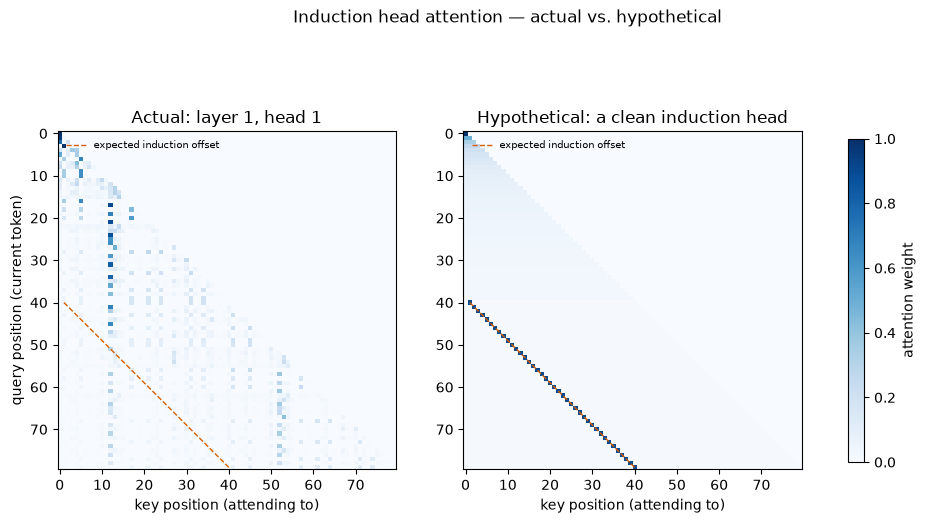

In [38]:
torch.manual_seed(1)
T = attn_maps[best_layer][best_head].shape[0]

ideal_induction_attn = torch.zeros(T, T)
for i in range(T):
    valid = i + 1
    if i < L:
        ideal_induction_attn[i, :valid] = 1.0 / valid  # nothing to lock onto yet: diffuse
    else:
        j = i - L + 1
        ideal_induction_attn[i, :valid] = 0.01  # faint baseline
        ideal_induction_attn[i, j] = 0.9  # crisp induction spike

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(attn, cmap="Blues", vmin=0, vmax=1)
axes[0].plot(j_vals, i_vals, color=HIGHLIGHT, linewidth=1, linestyle="--", label="expected induction offset")
axes[0].set_xlabel("key position (attending to)")
axes[0].set_ylabel("query position (current token)")
axes[0].set_title(f"Actual: layer {best_layer}, head {best_head}")
axes[0].legend(loc="upper left", fontsize=7, frameon=False)

im1 = axes[1].imshow(ideal_induction_attn.numpy(), cmap="Blues", vmin=0, vmax=1)
axes[1].plot(j_vals, i_vals, color=HIGHLIGHT, linewidth=1, linestyle="--", label="expected induction offset")
axes[1].set_xlabel("key position (attending to)")
axes[1].set_title("Hypothetical: a clean induction head")
axes[1].legend(loc="upper left", fontsize=7, frameon=False)

fig.colorbar(im1, ax=axes, label="attention weight", shrink=0.7)
fig.suptitle("Induction head attention \u2014 actual vs. hypothetical")
plt.show()

## 9. For comparison: the strongest previous-token head

This is the simpler circuit component induction heads typically compose
with. Notice the bright stripe sits directly on the `i -> i-1` diagonal
*everywhere*, not just in the second half — "look at the previous token"
doesn't depend on anything repeating.

strongest previous-token head: layer 3, head 0 (score=0.306)


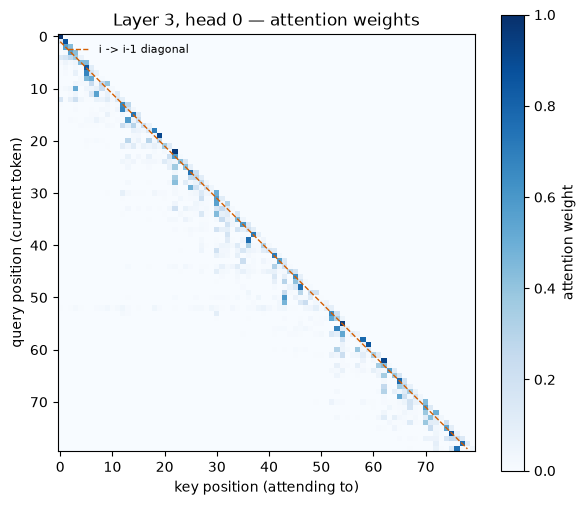

In [39]:
prev_values = prevtok_scores.flatten().numpy()
best_prev_idx = int(prev_values.argmax())
best_prev_layer, best_prev_head = divmod(best_prev_idx, n_heads_)
print(
    f"strongest previous-token head: layer {best_prev_layer}, head {best_prev_head} "
    f"(score={prev_values[best_prev_idx]:.3f})"
)

fig, ax = plt.subplots(figsize=(6, 6))
attn_prev = attn_maps[best_prev_layer][best_prev_head].numpy()
im = ax.imshow(attn_prev, cmap="Blues", vmin=0, vmax=attn_prev.max())
ax.plot(range(0, 2 * L - 1), range(1, 2 * L), color=HIGHLIGHT, linewidth=1, linestyle="--", label="i -> i-1 diagonal")
ax.set_xlabel("key position (attending to)")
ax.set_ylabel("query position (current token)")
ax.set_title(f"Layer {best_prev_layer}, head {best_prev_head} \u2014 attention weights")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.colorbar(im, ax=ax, label="attention weight", shrink=0.8)
plt.tight_layout()
plt.show()

**Same comparison for the previous-token head.** A clean one would put
almost all its weight on the `i -> i-1` diagonal for *every* query position
(no dependence on anything repeating — "look one step back" always
applies), giving one thin, dark, unbroken line the full length of the
matrix. The actual head already gets the right diagonal, just fainter and
less consistent — some rows barely light up on it at all, which is why its
score (0.31) is well below where a fully-formed version would sit (~0.9+).
Again, the right panel is synthetic, not measured.

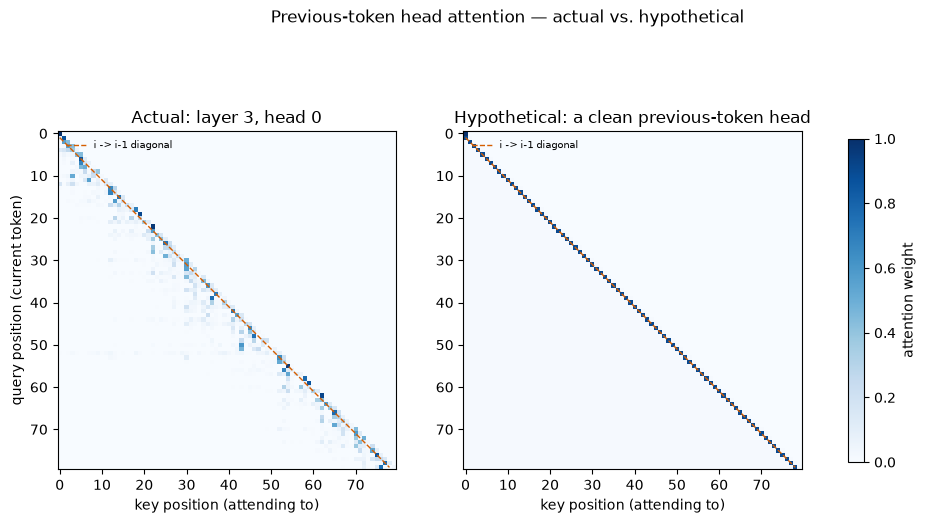

In [40]:
ideal_prevtok_attn = torch.zeros(T, T)
for i in range(T):
    valid = i + 1
    if i == 0:
        ideal_prevtok_attn[i, 0] = 1.0
    else:
        ideal_prevtok_attn[i, :valid] = 0.01
        ideal_prevtok_attn[i, i - 1] = 0.9

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(attn_prev, cmap="Blues", vmin=0, vmax=1)
axes[0].plot(range(0, T - 1), range(1, T), color=HIGHLIGHT, linewidth=1, linestyle="--", label="i -> i-1 diagonal")
axes[0].set_xlabel("key position (attending to)")
axes[0].set_ylabel("query position (current token)")
axes[0].set_title(f"Actual: layer {best_prev_layer}, head {best_prev_head}")
axes[0].legend(loc="upper left", fontsize=7, frameon=False)

im1 = axes[1].imshow(ideal_prevtok_attn.numpy(), cmap="Blues", vmin=0, vmax=1)
axes[1].plot(range(0, T - 1), range(1, T), color=HIGHLIGHT, linewidth=1, linestyle="--", label="i -> i-1 diagonal")
axes[1].set_xlabel("key position (attending to)")
axes[1].set_title("Hypothetical: a clean previous-token head")
axes[1].legend(loc="upper left", fontsize=7, frameon=False)

fig.colorbar(im1, ax=axes, label="attention weight", shrink=0.7)
fig.suptitle("Previous-token head attention \u2014 actual vs. hypothetical")
plt.show()

## Notes

- If the induction scores above look low or noisy, that's a real
  possibility for a model this small trained this briefly — clean
  induction heads are most cleanly documented in larger models trained
  longer. Try: a different `random.seed(...)` / snippet in section 6, a
  smaller or larger `L`, or training `train_shakespeare.ipynb` for more
  steps, then re-running this notebook.
- Everything here reads `gpt.py` and `gpt_shakespeare.pt` unmodified — no
  changes were made to the model or training code to enable this probe.